# 04 - Sampling bias and robustness
Respondents self-select. We (1) reweight 2024/2025 to the 2023 respondent mix and (2) re-estimate the key associations under alternative specifications. (Outputs come from `python -m src.robustness`; the ordered logits take several minutes, so this notebook reads the saved results.)

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)

In [2]:
rw = pd.read_csv("reports/tables/robustness_reweighted_trend.csv")
rw.pivot_table(index=["metric", "survey_year"], columns="version", values="share").round(3)

version               Reweighted to 2023 respondent mix  Unweighted
metric   survey_year                                               
Adoption 2023                                     0.442       0.442
         2024                                     0.621       0.633
         2025                                     0.817       0.808
Distrust 2023                                     0.251       0.251
         2024                                     0.328       0.313
         2025                                     0.386       0.380
Trust    2023                                     0.463       0.463
         2024                                     0.408       0.414
         2025                                     0.383       0.384

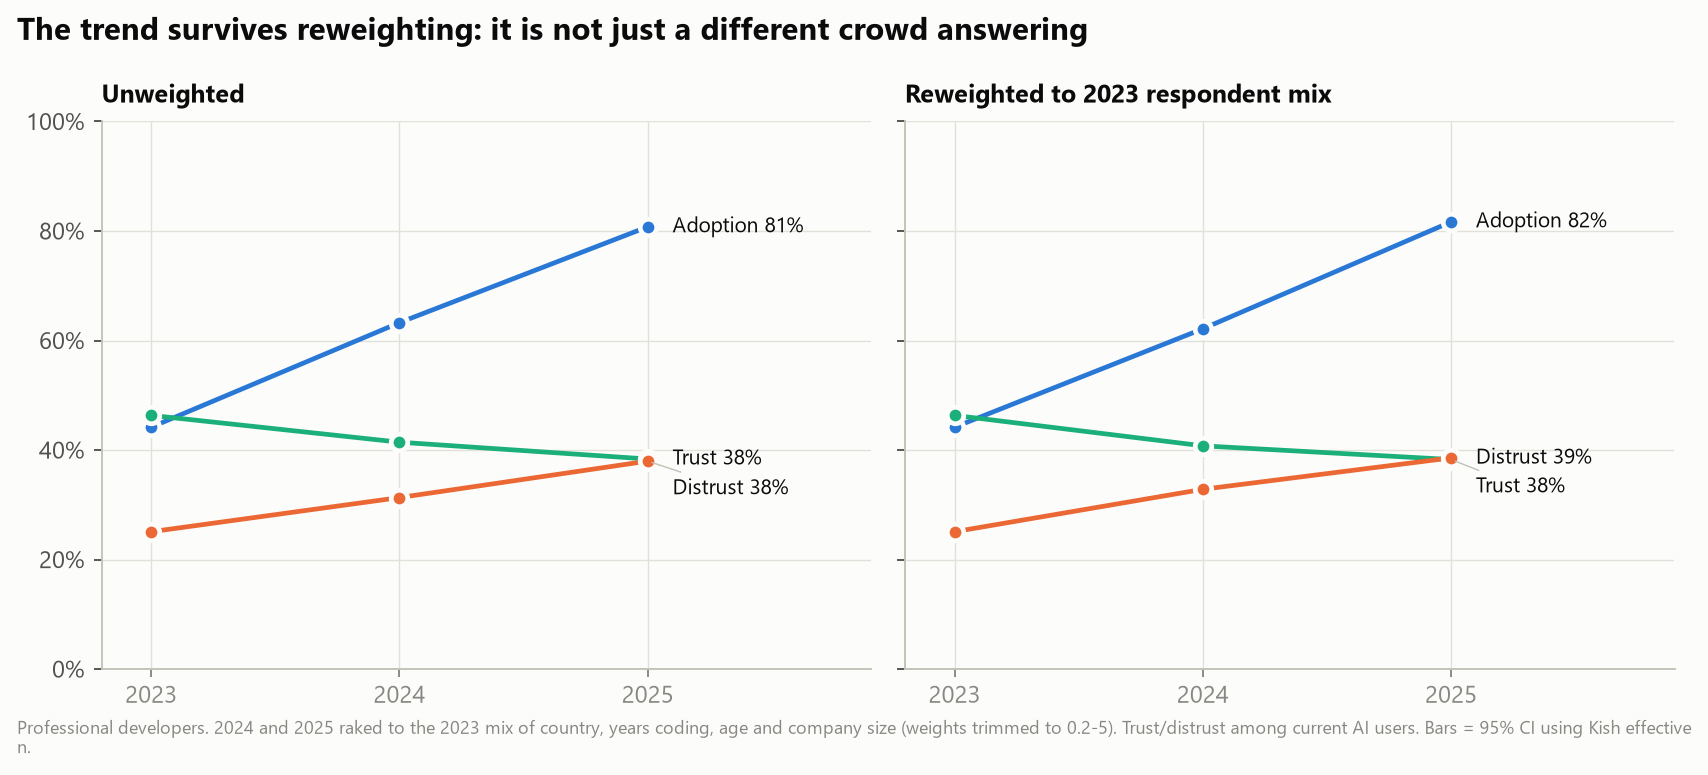

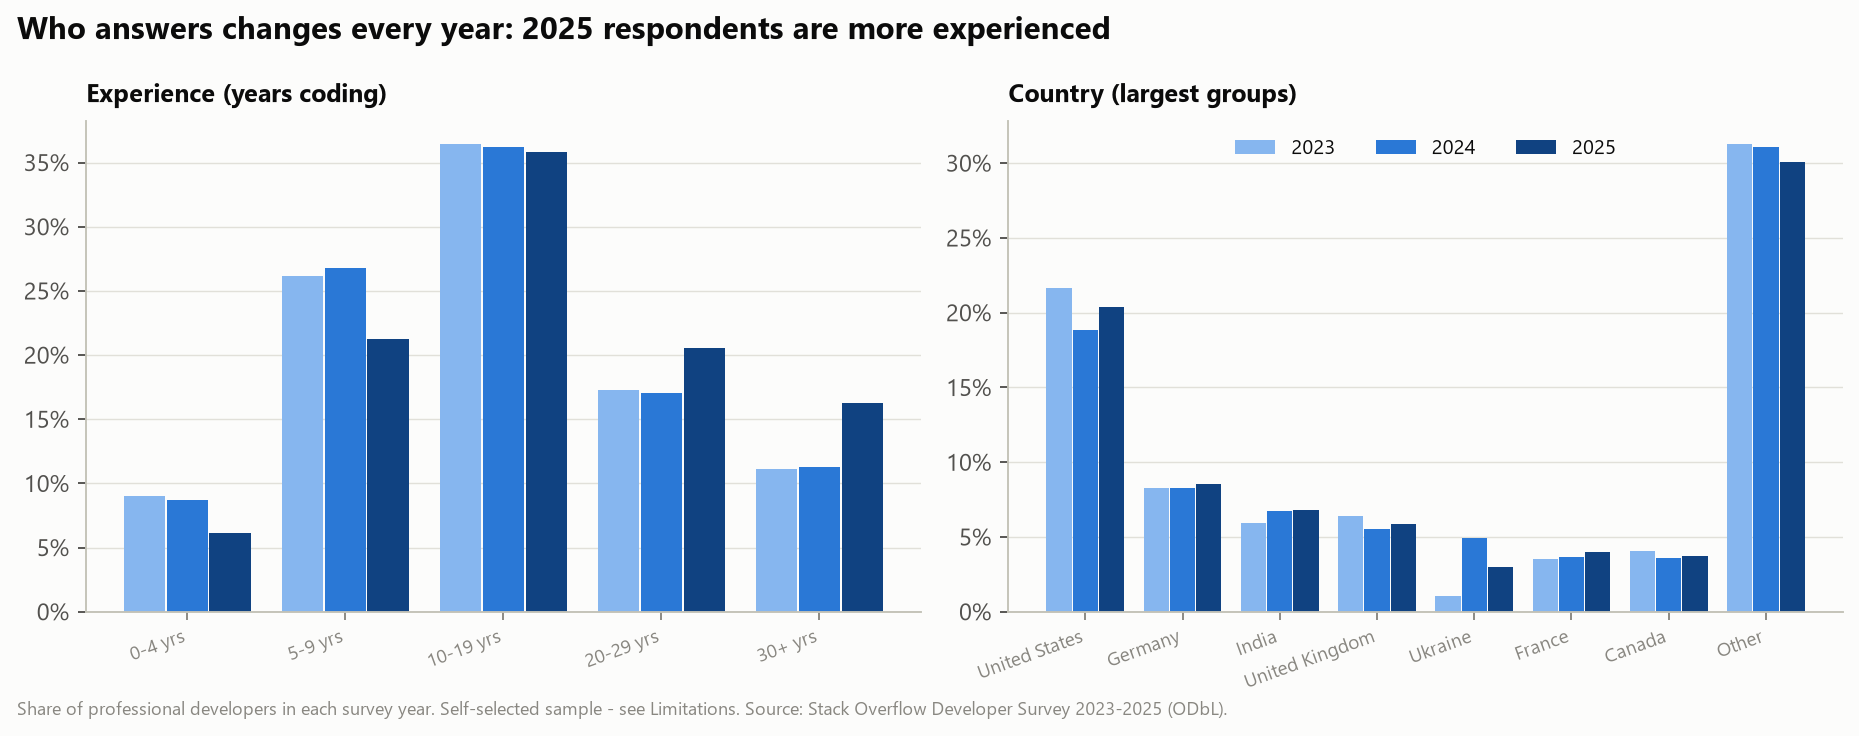

In [3]:
display(Image("reports/figures/fig15_reweighted_trend.png", width=880))
display(Image("reports/figures/fig11_sample_composition.png", width=880))

In [4]:
rob = pd.read_csv("reports/tables/robustness_models.csv")
rob.pivot_table(index="spec", columns="key_term", values="odds_ratio").round(2)

key_term,"'Almost right, but not quite' (2025)",'Debugging AI code takes longer' (2025),Experience 30+ yrs vs 0-4 yrs,Trust fell over time (year 2025 vs 2023),Uses AI monthly or less vs daily (2025)
spec,,,,,
"A. Baseline: pooled logit, professional AI users",NaN,NaN,3.07,1.87,NaN
B. Ordered logit on 5-point trust scale,NaN,NaN,2.95,1.58,NaN
C. Outcome = 'highly distrust' only,NaN,NaN,4.44,2.29,NaN
D. Excluding the United States,NaN,NaN,3.25,1.80,NaN
E. Complete cases only (no 'Missing' categories),NaN,NaN,2.96,1.89,NaN
F. Professional experience instead of years coding,NaN,NaN,1.52,1.88,NaN
G. Weighted to 2023 respondent mix,NaN,NaN,3.19,1.90,NaN
H. All respondents who use AI (not only professionals),NaN,NaN,3.48,1.87,NaN
I. 2025: 'almost right' entered alone (no other frustrations),1.08,NaN,3.13,NaN,3.37


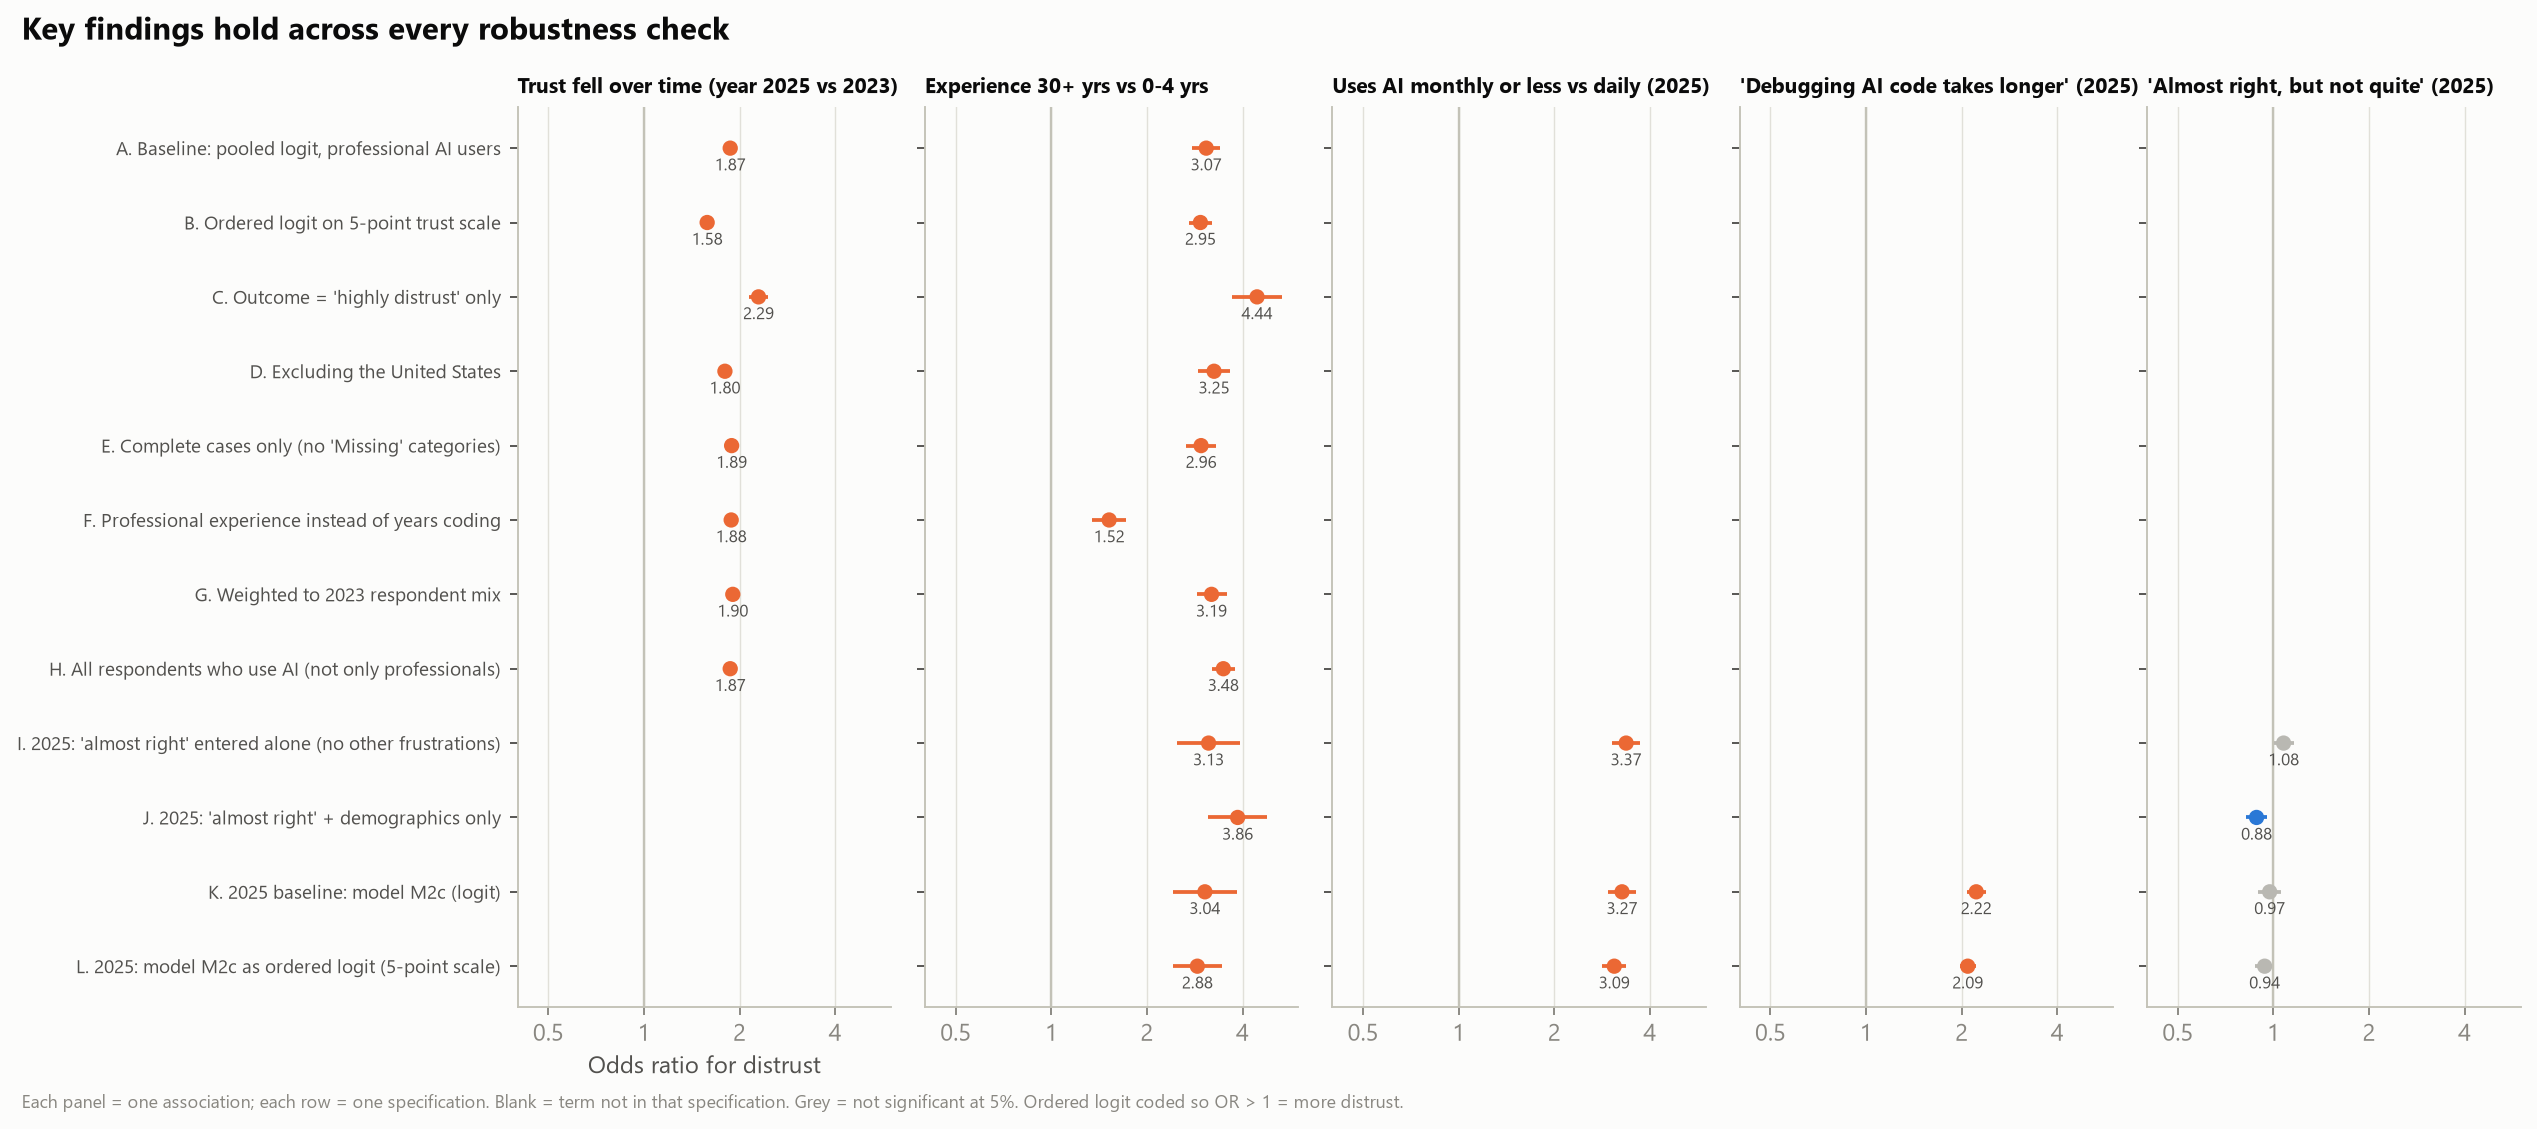

In [5]:
display(Image("reports/figures/fig14_robustness.png", width=1000))

## Limitations
* Self-selected, Stack Overflow-engaged sample; reweighting only fixes *observed* composition.
* 2025 AI section was optional: ~31% of 2025 respondents skipped it.
* Wording/option changes are documented in `mappings/question_crosswalk.csv`; tier-C questions are analysed within one year only.
* Cross-sectional self-reports - associations, not causes.